# Vendor Risk Scoring — Model Training & Evaluation

MediSource AI / `risk_intelligence` service.

This notebook reproduces, cell by cell, exactly what the running service does at
`services/risk_intelligence/app/model.py` + `app/mlflow_utils.py` when it trains and
registers the vendor-risk model — same functions, same seeds, same hyperparameters —
so the dataset, model, and metrics saved by this notebook match what the deployed
service serves from its MLflow registry.

It also demonstrates the second, separate ML component of the service: the
unsupervised `IsolationForest` anomaly detector in `app/anomaly.py`, which (unlike
the risk model) is *not* a single persisted model — it fits fresh per vendor, per
assessment, on that vendor's own invoice history.

**Why the training data is synthetic.** There is no labeled historical dataset for a
from-scratch hospital procurement deployment — no real vendor has yet accumulated a
"confirmed compliance incident" outcome to learn from. `generate_training_data()`
samples the 17 feature values from distributions shaped like real procurement data,
then derives labels from an explicit, documented heuristic formula (`_synthetic_label`)
plus small Gaussian noise. This keeps the *pipeline* (training → MLflow tracking →
versioned registry → inference) genuinely real and swappable, while being honest that
the initial weights encode domain heuristics rather than fitted historical outcomes.
`train_model()` is the exact entrypoint that would be pointed at real labeled outcomes
later, with no change to the serving path.


In [1]:
import sys
from pathlib import Path

SERVICE_ROOT = Path.cwd().parent  # notebooks/ -> services/risk_intelligence/
sys.path.insert(0, str(SERVICE_ROOT))

import json
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from app.features import FEATURE_NAMES
from app.model import RISK_DIMENSIONS, generate_training_data, train_model
from app.anomaly import detect

print("scikit-learn", sklearn.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)
print(len(FEATURE_NAMES), "features:", FEATURE_NAMES)
print(len(RISK_DIMENSIONS), "risk dimensions:", RISK_DIMENSIONS)


scikit-learn 1.5.2
numpy 1.26.4
pandas 2.2.2
17 features: ['license_days_to_expiry', 'gstin_valid', 'watchlist_hit', 'years_in_business', 'cold_chain_violation_count', 'financial_health_score', 'prior_compliance_flags', 'late_delivery_rate', 'doc_fraud_flag_rate', 'doc_mean_fraud_score', 'duplicate_invoice_rate', 'log_total_spend', 'spend_volatility', 'spend_growth_ratio', 'max_amount_zscore', 'round_amount_rate', 'anomaly_score']
6 risk dimensions: ['compliance_risk', 'fraud_risk', 'financial_risk', 'supplier_risk', 'spend_risk', 'operational_risk']


## 1. Dataset

Generated by `app.model.generate_training_data()` — 4,000 synthetic vendor observations, 17 features sampled from distributions shaped like real procurement data (licence expiry, fraud-flag rate, spend volatility, ...), labeled by the documented heuristic in `_synthetic_label()` plus noise. Seeded (`seed=42`) for reproducibility.

In [2]:
X, y = generate_training_data(n=4000, seed=42)

df = pd.DataFrame(X, columns=FEATURE_NAMES)
for i, dim in enumerate(RISK_DIMENSIONS):
    df[dim] = y[:, i]

DATA_DIR = SERVICE_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
csv_path = DATA_DIR / "vendor_risk_training_data.csv"
df.to_csv(csv_path, index=False)

print(f"{df.shape[0]} rows x {df.shape[1]} cols -> {csv_path.relative_to(SERVICE_ROOT)}")
df.head()


4000 rows x 23 cols -> data/vendor_risk_training_data.csv


,license_days_to_expiry,gstin_valid,watchlist_hit,years_in_business,cold_chain_violation_count,financial_health_score,prior_compliance_flags,late_delivery_rate,doc_fraud_flag_rate,doc_mean_fraud_score,...,spend_growth_ratio,max_amount_zscore,round_amount_rate,anomaly_score,compliance_risk,fraud_risk,financial_risk,supplier_risk,spend_risk,operational_risk
0,558.206597,1.0,0.0,12.951642,1.0,0.867897,0.0,0.075944,0.123066,0.023894,...,0.601421,2.314510,0.289400,0.022987,0.036393,0.020754,0.266723,0.121932,0.393218,0.094244
1,303.547614,1.0,0.0,8.840848,0.0,0.571038,0.0,0.171413,0.044893,0.025093,...,0.544068,2.033209,0.099479,0.112850,0.000000,0.020552,0.329588,0.052845,0.301555,0.022138
2,622.534419,1.0,0.0,1.876396,0.0,0.617411,3.0,0.179162,0.105060,0.096543,...,0.515972,1.929681,0.054723,0.015022,0.230341,0.036472,0.522135,0.132465,0.529567,0.106018
3,499.999702,1.0,0.0,24.774300,0.0,0.761385,2.0,0.260679,0.053238,0.065275,...,1.197707,1.232427,0.189024,0.340155,0.170841,0.011615,0.277296,0.155721,0.313836,0.075680
4,41.574784,1.0,0.0,4.369343,2.0,0.511162,0.0,0.041435,0.052889,0.055005,...,1.572810,4.111488,0.103664,0.178957,0.181891,0.000000,0.369286,0.175233,0.342537,0.224592


In [3]:
df[RISK_DIMENSIONS].describe().T


,count,mean,std,min,25%,50%,75%,max
compliance_risk,4000.0,0.121916,0.178350,0.000000,0.005029,0.065065,0.164028,0.946339
fraud_risk,4000.0,0.081159,0.071905,0.000000,0.042589,0.070455,0.099397,0.552751
financial_risk,4000.0,0.371039,0.137379,0.018255,0.271051,0.362022,0.462789,0.846049
supplier_risk,4000.0,0.158659,0.096618,0.000000,0.086899,0.146742,0.219282,0.647490
spend_risk,4000.0,0.349017,0.131892,0.018064,0.253852,0.337646,0.438304,0.955421
operational_risk,4000.0,0.115191,0.095375,0.000000,0.042700,0.096665,0.163916,0.676908


### Feature / label correlation

A quick sanity check that the synthetic labels actually respond to the features they are supposed to (rather than being pure noise).

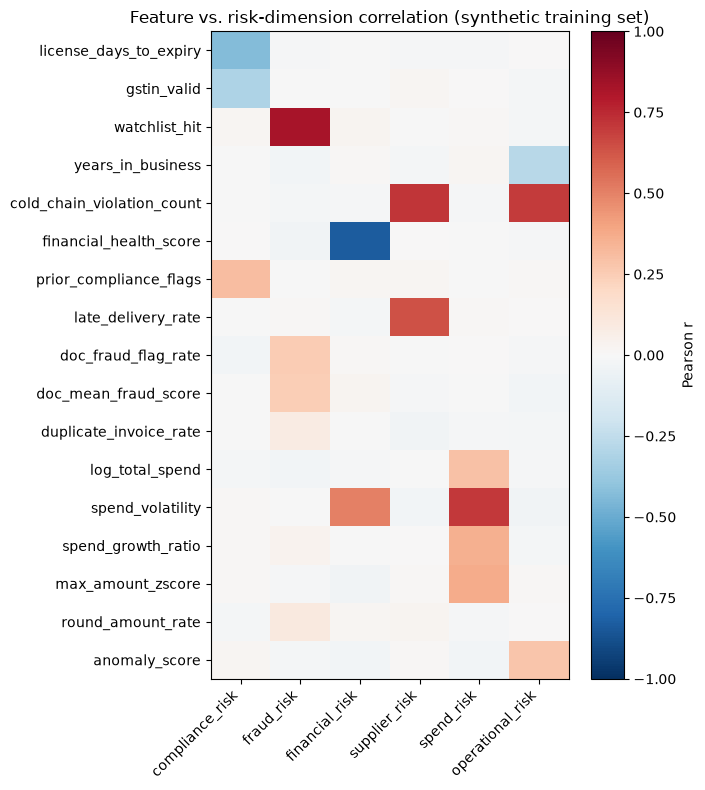

In [4]:
corr = df.corr(numeric_only=True)[RISK_DIMENSIONS].loc[FEATURE_NAMES]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(RISK_DIMENSIONS)))
ax.set_xticklabels(RISK_DIMENSIONS, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURE_NAMES)))
ax.set_yticklabels(FEATURE_NAMES)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Feature vs. risk-dimension correlation (synthetic training set)")
fig.tight_layout()
plt.show()


## 2. Train

`train_model()` splits 80/20, fits a `MultiOutputRegressor` wrapping one `GradientBoostingRegressor` per risk dimension (`n_estimators=150, max_depth=3, learning_rate=0.08`), and returns the fitted model plus a metrics dict — identical to what `mlflow_utils.train_and_register()` logs to MLflow at runtime.

In [5]:
model, metrics = train_model()
metrics


{'mean_absolute_error': 0.023636008222240334,
 'n_train': 3200,
 'n_test': 800,
 'n_features': 17,
 'n_dimensions': 6}

In [6]:
# same split train_model() used internally, recovered here for per-dimension evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
preds = model.predict(X_test)

per_dim_mae = {
    dim: float(np.mean(np.abs(preds[:, i] - y_test[:, i])))
    for i, dim in enumerate(RISK_DIMENSIONS)
}
pd.Series(per_dim_mae, name="MAE").to_frame()


,MAE
compliance_risk,0.021099
fraud_risk,0.023716
financial_risk,0.024014
supplier_risk,0.024126
spend_risk,0.026152
operational_risk,0.022709


### Feature importances

Each of the six `GradientBoostingRegressor` estimators inside the `MultiOutputRegressor` exposes its own `feature_importances_`.

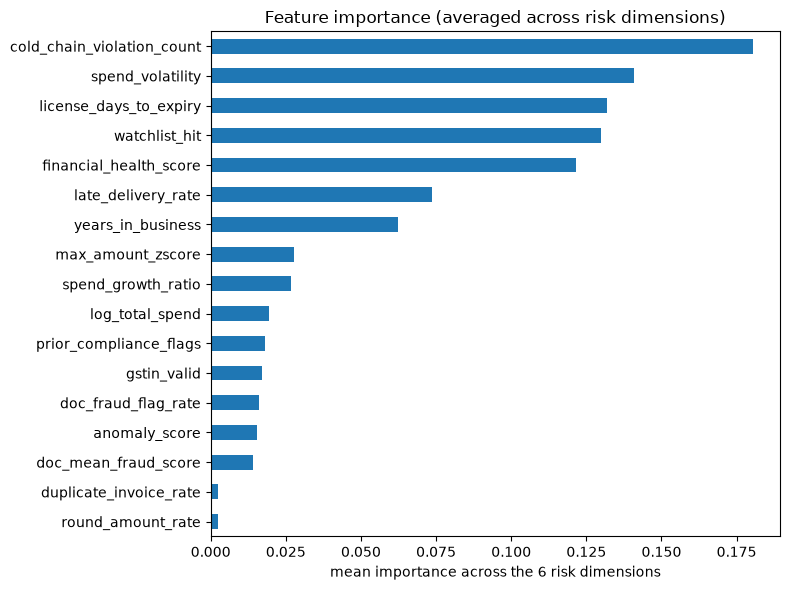

,compliance_risk,fraud_risk,financial_risk,supplier_risk,spend_risk,operational_risk
license_days_to_expiry,0.7861,0.0022,0.0003,0.0008,0.0003,0.0010
gstin_valid,0.1022,0.0002,0.0000,0.0000,0.0000,0.0000
watchlist_hit,0.0000,0.7797,0.0000,0.0000,0.0000,0.0000
years_in_business,0.0002,0.0018,0.0007,0.0010,0.0005,0.3705
cold_chain_violation_count,0.0000,0.0003,0.0001,0.5514,0.0000,0.5307
financial_health_score,0.0003,0.0028,0.7223,0.0017,0.0004,0.0012
prior_compliance_flags,0.1085,0.0003,0.0000,0.0002,0.0000,0.0000
late_delivery_rate,0.0002,0.0032,0.0004,0.4363,0.0006,0.0009
doc_fraud_flag_rate,0.0002,0.0938,0.0003,0.0010,0.0008,0.0010
doc_mean_fraud_score,0.0001,0.0823,0.0008,0.0009,0.0003,0.0008


In [7]:
importances = pd.DataFrame(
    {dim: est.feature_importances_ for dim, est in zip(RISK_DIMENSIONS, model.estimators_)},
    index=FEATURE_NAMES,
)

fig, ax = plt.subplots(figsize=(8, 6))
importances.mean(axis=1).sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("mean importance across the 6 risk dimensions")
ax.set_title("Feature importance (averaged across risk dimensions)")
fig.tight_layout()
plt.show()

importances.round(4)


## 3. Save artifacts

Model as a joblib-pickled `.pkl`, metrics + feature importances as JSON — the same files this notebook ships alongside it in `models/` and `results/`.

In [8]:
MODELS_DIR = SERVICE_ROOT / "models"
RESULTS_DIR = SERVICE_ROOT / "results"
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

pkl_path = MODELS_DIR / "vendor_risk_model.pkl"
joblib.dump(model, pkl_path)

results = {
    "model_type": "MultiOutputRegressor(GradientBoostingRegressor)",
    "sklearn_version": sklearn.__version__,
    "hyperparameters": {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.08, "random_state": 42},
    "dataset": {
        "source": "app.model.generate_training_data (synthetic, heuristic-labeled)",
        "n_samples": int(X.shape[0]),
        "n_features": len(FEATURE_NAMES),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "feature_names": FEATURE_NAMES,
        "risk_dimensions": RISK_DIMENSIONS,
        "seed": 42,
    },
    "metrics": {
        "overall_mean_absolute_error": metrics["mean_absolute_error"],
        "per_dimension_mean_absolute_error": per_dim_mae,
    },
    "feature_importances": {dim: importances[dim].to_dict() for dim in RISK_DIMENSIONS},
}
metrics_path = RESULTS_DIR / "training_metrics.json"
metrics_path.write_text(json.dumps(results, indent=2))

print("saved:", pkl_path.relative_to(SERVICE_ROOT))
print("saved:", metrics_path.relative_to(SERVICE_ROOT))


saved: models/vendor_risk_model.pkl
saved: results/training_metrics.json


### Reload check

Confirms the pickled file round-trips to predictions identical to the in-memory model — this is the same load path `mlflow_utils.get_or_train_model()` uses (via `mlflow.sklearn.load_model`, which is joblib underneath).

In [9]:
reloaded = joblib.load(pkl_path)
sample = X_test[:3]
np.testing.assert_allclose(reloaded.predict(sample), model.predict(sample))
print("round-trip OK — reloaded model matches in-memory model on", len(sample), "held-out rows")

pd.DataFrame(np.clip(model.predict(sample), 0, 1), columns=RISK_DIMENSIONS).round(3)


round-trip OK — reloaded model matches in-memory model on 3 held-out rows


,compliance_risk,fraud_risk,financial_risk,supplier_risk,spend_risk,operational_risk
0,0.012,0.079,0.288,0.206,0.216,0.167
1,0.865,0.096,0.332,0.500,0.423,0.402
2,0.087,0.052,0.116,0.212,0.259,0.468


## 4. Anomaly detection (`app/anomaly.py`)

A separate, unsupervised layer: instead of scoring a vendor against patterns anticipated up front, this asks whether a vendor is behaving unlike its own history or unlike its peers. It combines an `IsolationForest` fit on that vendor's own invoice-amount history with three named rules (spend spike, peer-outlier invoice, invoice burst) that give a human-readable reason rather than a bare score.

**No single model is persisted here** — `detect()` fits a fresh forest per vendor at assessment time from `app.analytics.spend_series()`. What follows is a demonstration run against three synthetic vendor invoice histories, to show real input/output shapes.

In [10]:
from datetime import datetime, timedelta

rng = np.random.default_rng(7)
start = datetime(2025, 1, 1)

def make_series(n, base, noise_frac, spike_at=None, spike_mult=4.0, burst_at=None, burst_n=0):
    series, day = [], 0
    for i in range(n):
        day += int(rng.integers(10, 18))
        amount = base * (1 + rng.normal(0, noise_frac))
        if spike_at is not None and i == spike_at:
            amount = base * spike_mult
        series.append((start + timedelta(days=day), max(amount, 100.0)))
    if burst_at is not None:
        anchor = series[burst_at][0]
        for j in range(burst_n):
            series.append((anchor + timedelta(days=j % 6), base * (1 + rng.normal(0, noise_frac))))
        series.sort(key=lambda t: t[0])
    return series

vendors = {
    "VEND-NORMAL-001": make_series(14, base=42000, noise_frac=0.12),
    "VEND-SPENDSPIKE-002": make_series(14, base=38000, noise_frac=0.10, spike_at=13, spike_mult=5.0),
    "VEND-BURST-003": make_series(10, base=51000, noise_frac=0.10, burst_at=6, burst_n=6),
}

all_amounts = [a for series in vendors.values() for _, a in series]
peer_mean, peer_stdev = float(np.mean(all_amounts)), float(np.std(all_amounts))

anomaly_rows, anomaly_results = [], {}
for vendor_id, series in vendors.items():
    for ts, amount in series:
        anomaly_rows.append({"vendor_id": vendor_id, "timestamp": ts.isoformat(), "amount": round(amount, 2)})
    anomaly_results[vendor_id] = detect(series, peer_mean=peer_mean, peer_stdev=peer_stdev)

anomaly_df = pd.DataFrame(anomaly_rows)
anomaly_csv = DATA_DIR / "anomaly_demo_vendor_invoices.csv"
anomaly_df.to_csv(anomaly_csv, index=False)

anomaly_out = {
    "description": (
        "Illustrative detect() run against three synthetic vendor invoice histories. "
        "Not training data -- detect() fits per vendor at request time; there is no "
        "persisted anomaly model."
    ),
    "peer_baseline": {"mean": peer_mean, "stdev": peer_stdev},
    "vendors": anomaly_results,
}
anomaly_json = RESULTS_DIR / "anomaly_demo_results.json"
anomaly_json.write_text(json.dumps(anomaly_out, indent=2))

print("saved:", anomaly_csv.relative_to(SERVICE_ROOT))
print("saved:", anomaly_json.relative_to(SERVICE_ROOT))
pd.DataFrame(anomaly_results).T


saved: data/anomaly_demo_vendor_invoices.csv
saved: results/anomaly_demo_results.json


,anomaly_score,anomaly_flag,reasons
VEND-NORMAL-001,0.4409,False,[]
VEND-SPENDSPIKE-002,1.0,True,[latest invoice is a statistical outlier again...
VEND-BURST-003,0.9826,True,[spend rose 6.8x versus the previous 90 days]


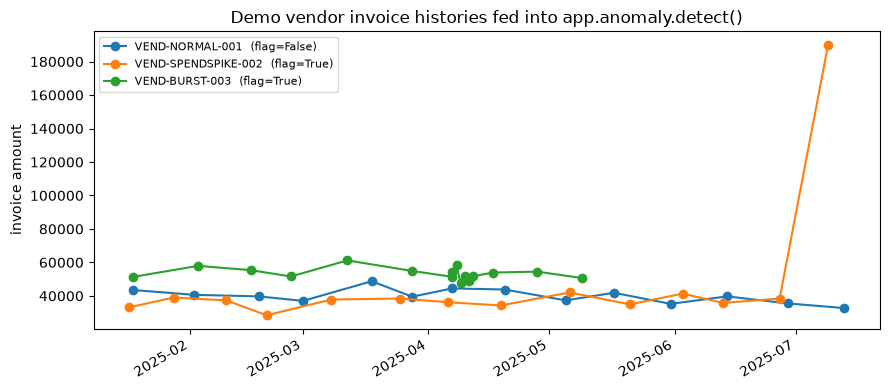

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for vendor_id, series in vendors.items():
    ts = [t for t, _ in series]
    amt = [a for _, a in series]
    ax.plot(ts, amt, marker="o", label=f"{vendor_id}  (flag={anomaly_results[vendor_id]['anomaly_flag']})")
ax.set_ylabel("invoice amount")
ax.set_title("Demo vendor invoice histories fed into app.anomaly.detect()")
ax.legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## 5. Summary

| Artifact | Path | Produced by |
|---|---|---|
| Training dataset | `data/vendor_risk_training_data.csv` | `generate_training_data()` |
| Trained model | `models/vendor_risk_model.pkl` | `train_model()`, pickled with `joblib` |
| Model card | `models/vendor_risk_model_card.json` | input/output schema for the `.pkl` |
| Training metrics + feature importances | `results/training_metrics.json` | this notebook |
| Anomaly demo invoices | `data/anomaly_demo_vendor_invoices.csv` | synthetic, for illustration |
| Anomaly demo results | `results/anomaly_demo_results.json` | `app.anomaly.detect()` |

In the deployed system, MLflow (not this notebook) is the source of truth for the risk model: `mlflow_utils.train_and_register()` runs this same training code inside the `risk_intelligence` container on first boot, logs params/metrics/the model artifact to the MLflow tracking server, registers a model version, and promotes it to `Production`. The `.pkl` and JSON files here are a static, offline export of one such run for inspection and submission — not something the running service reads from.